# Analyse RFM (Recency, Frequency, Monetary)

## Objectif
Cette analyse vise à segmenter les clients de ClassicModels selon leur comportement d’achat
afin d’identifier les clients VIP, réguliers, à risque et perdus.

## Intérêt métier
La segmentation RFM permet :
- de prioriser les clients à forte valeur,
- d’identifier les clients en risque de churn,
- d’adapter les stratégies marketing et commerciales.

## Justification de l’analyse

Le modèle RFM est une méthode reconnue en analyse client permettant de mesurer la valeur
d’un client à partir de trois dimensions :
- Recency : récence du dernier achat
- Frequency : fréquence d’achat
- Monetary : montant total dépensé

Cette approche est particulièrement adaptée aux bases transactionnelles comme ClassicModels
et permet une segmentation simple, interprétable et actionnable.

In [14]:
# Suppression des warnings non bloquants pour améliorer la lisibilité du notebook
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [1]:
from pathlib import Path

HERE = Path().resolve()
HERE

WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis/notebooks/part4_advanced_analysis')

In [2]:
from pathlib import Path

PROJECT_ROOT = None
for p in Path().resolve().parents:
    if (p / "requirements.txt").exists() and (p / "visualizations").exists():
        PROJECT_ROOT = p
        break

PROJECT_ROOT

WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis')

In [3]:
OUTPUT_DIR = PROJECT_ROOT / "visualizations" / "part4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR

WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis/visualizations/part4')

In [4]:
from pathlib import Path

# Racine du projet (on remonte depuis notebooks/part4_advanced_analysis)
PROJECT_ROOT = Path().resolve().parents[2]

OUTPUT_DIR = PROJECT_ROOT / "visualizations" / "part4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR  

WindowsPath('C:/Users/canpe/Documents/visualizations/part4')

In [5]:
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../../"))
sys.path.append(PROJECT_ROOT)

In [6]:
import pandas as pd
import numpy as np
from datetime import datetime

from src.analysis.db import get_connection

In [7]:
conn = get_connection()
print(conn)
conn.close()

In [8]:
def fetch_df(query, params=None):
    conn = get_connection()
    df = pd.read_sql(query, conn, params=params)
    conn.close()
    return df

Je centralise la connexion + extraction SQL dans une fonction unique pour éviter la duplication, réduire les erreurs, et garantir la fermeture systématique de la connexion.

In [9]:
rfm_sql = """
SELECT
    c.customerNumber,
    c.customerName,
    MAX(p.paymentDate) AS last_payment_date,
    COUNT(p.checkNumber) AS frequency,
    SUM(p.amount) AS monetary
FROM customers c
JOIN payments p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName;
"""

rfm = fetch_df(rfm_sql)
rfm.head()

C:\Users\canpe\AppData\Local\Temp\ipykernel_75524\1589009945.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


,customerNumber,customerName,last_payment_date,frequency,monetary
0,103,Atelier graphique,2004-12-18,3,22314.36
1,112,Signal Gift Stores,2004-12-17,3,80180.98
2,114,"Australian Collectors, Co.",2004-12-15,4,180585.07
3,119,La Rochelle Gifts,2005-02-22,3,116949.68
4,121,Baane Mini Imports,2004-11-28,4,104224.79


In [10]:
rfm["last_payment_date"] = pd.to_datetime(rfm["last_payment_date"])

ref_date = rfm["last_payment_date"].max()  # date la plus récente du dataset
rfm["recency"] = (ref_date - rfm["last_payment_date"]).dt.days

rfm[["customerNumber","customerName","recency","frequency","monetary"]].head()

,customerNumber,customerName,recency,frequency,monetary
0,103,Atelier graphique,173,3,22314.36
1,112,Signal Gift Stores,174,3,80180.98
2,114,"Australian Collectors, Co.",176,4,180585.07
3,119,La Rochelle Gifts,107,3,116949.68
4,121,Baane Mini Imports,193,4,104224.79


On prend comme référence la date la plus récente du dataset pour éviter un biais si la base n’est pas à jour “aujourd’hui”.

In [11]:
rfm["R_score"] = pd.qcut(rfm["recency"], 4, labels=[4,3,2,1])  # plus récent = meilleur score
rfm["F_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 4, labels=[1,2,3,4])
rfm["M_score"] = pd.qcut(rfm["monetary"], 4, labels=[1,2,3,4])

rfm["RFM_score"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)

rfm.head()

,customerNumber,customerName,last_payment_date,frequency,monetary,recency,R_score,F_score,M_score,RFM_score
0,103,Atelier graphique,2004-12-18,3,22314.36,173,3,2,1,321
1,112,Signal Gift Stores,2004-12-17,3,80180.98,174,3,2,3,323
2,114,"Australian Collectors, Co.",2004-12-15,4,180585.07,176,3,4,4,344
3,119,La Rochelle Gifts,2005-02-22,3,116949.68,107,4,2,4,424
4,121,Baane Mini Imports,2004-11-28,4,104224.79,193,3,4,4,344


Les quartiles permettent de segmenter de façon robuste même si les distributions sont asymétriques (ce qui est fréquent en ventes).

In [12]:
def segment(row):
    r, f, m = int(row["R_score"]), int(row["F_score"]), int(row["M_score"])
    if r >= 3 and f >= 3 and m >= 3:
        return "VIP"
    if r >= 3 and (f >= 2 or m >= 2):
        return "Réguliers"
    if r == 1 and (f >= 3 or m >= 3):
        return "À risque"
    if r == 1 and f <= 2 and m <= 2:
        return "Perdus"
    return "Autres"

rfm["segment"] = rfm.apply(segment, axis=1)
rfm["segment"].value_counts()

segment
VIP          28
Autres       26
Perdus       21
Réguliers    19
À risque      4
Name: count, dtype: int64

La segmentation est construite pour être simple, interprétable et actionnable : relance des “à risque”, fidélisation des “VIP”, etc.

C:\Users\canpe\AppData\Local\Temp\ipykernel_75524\1276446533.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


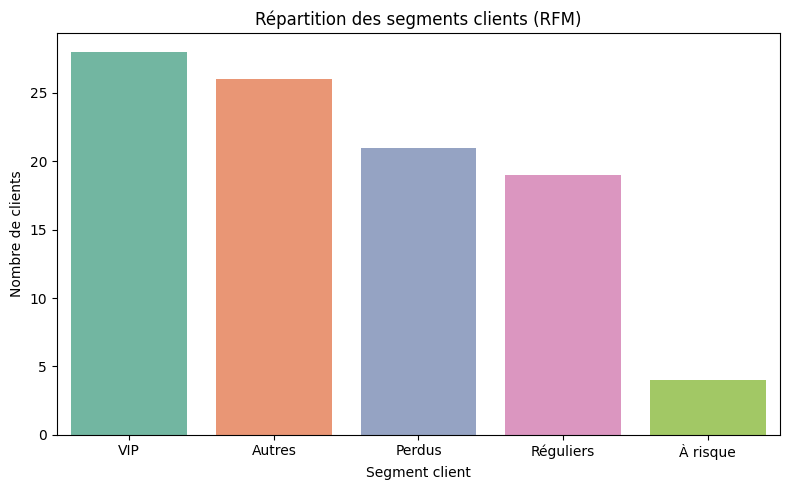

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(
    data=rfm,
    x="segment",
    order=rfm["segment"].value_counts().index,
    palette="Set2"
)

plt.title("Répartition des segments clients (RFM)")
plt.xlabel("Segment client")
plt.ylabel("Nombre de clients")
plt.tight_layout()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_rfm_segments.png", dpi=300, bbox_inches="tight")
plt.show()

Les figures sont sauvegardées via des chemins absolus calculés dynamiquement à partir de la racine du projet, afin de garantir la portabilité et la reproductibilité des analyses, indépendamment du dossier d’exécution des notebooks. 